# Zero-Order Hold: Multiple Shooting

Solve the Cartesian two-body TOPS `P0` benchmark with multiple shooting, following the first example in [Zero-Order Hold I](./udp_zoh_point2point.ipynb). The interior states are initialized by propagating from the fixed endpoints.

In [74]:
import pykep as pk
import numpy as np
import pygmo as pg
from matplotlib import pyplot as plt

In [75]:
ipopt = pg.ipopt()
ipopt.set_integer_options({"max_iter": 2000})
ipopt.set_numeric_options({"tol": 1e-10})
ipopt.set_string_options({"sb": "yes"})
algo = pg.algorithm(ipopt)

In [83]:
prob_name = "P0"
udp = pk.trajopt.gym.tops_twobody(prob_name, nseg=10, time_encoding="softmax", ms=True)
print(udp.extra_info)

prob = pg.problem(udp)
prob.c_tol = 1e-7
print("Variables:", prob.get_nx(), "Equalities:", prob.get_nec(), "Inequalities:", prob.get_nic())

Mildly-elliptic to mildly-elliptic transfer (e_s~0.201, e_f~0.210) in fixed tof -> T=0.22N, Isp=3000s
Variables: 115 Equalities: 70 Inequalities: 10


Initialize the internal states of each population member from its controls and time grid. A propagated state outside the node bounds raises `ValueError`. A finite defect or a feasible fitness alone does not establish that every segment propagation succeeded.

In [84]:
pop = pg.population(prob, 1)
for i, x in enumerate(pop.get_x()):
    pop.set_x(i, udp.guess_internal_states(x))

Compare the analytical gradient with finite differences. `prob.gradient_sparsity()` supplies the coordinates for either a sparse or dense gradient.

In [86]:
x = pop.champion_x
pattern = prob.gradient_sparsity()
jacobian = np.zeros((prob.get_nf(), prob.get_nx()))
jacobian[pattern[:, 0], pattern[:, 1]] = prob.gradient(x)
numerical = pg.estimate_gradient_h(prob.fitness, x, dx=1e-8).reshape(jacobian.shape)
grad_err = numerical - jacobian
grad_err.min(), grad_err.max()

(-1.0748347064465369e-07, 1.134445504272219e-07)

In [87]:
pop = algo.evolve(pop)
print("Feasible:", prob.feasibility_f(pop.champion_f))
print("Objective:", pop.champion_f[0])
print("Final mass:", pop.champion_x[0] * udp.MASS)
print("Final tof:", pop.champion_x[4 * udp.nseg + 1] * udp.TIME)

Feasible: False
Objective: -0.81394925764
Final mass: 0.81394925764
Final tof: 11.0


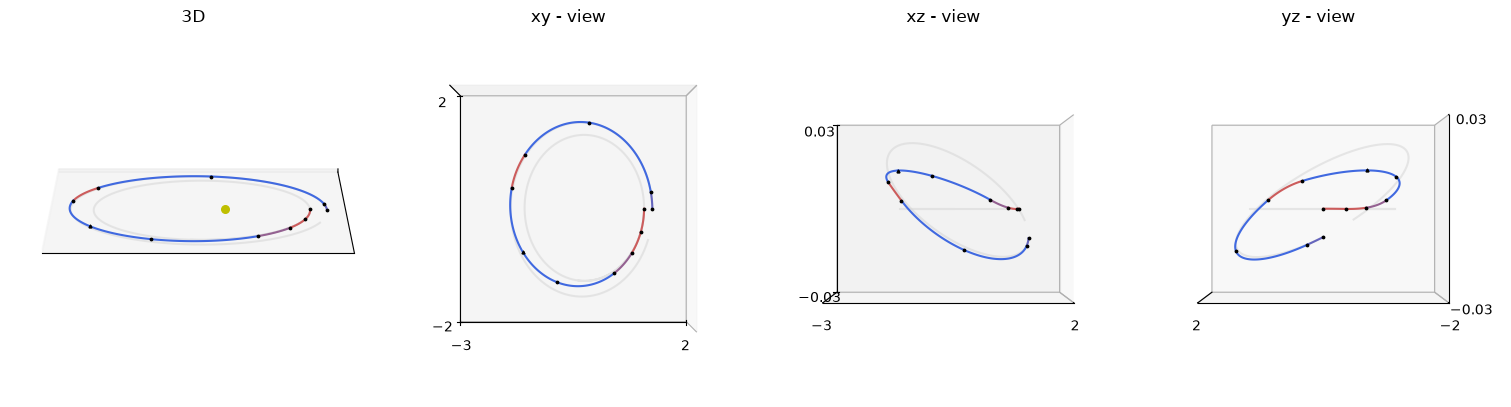

In [81]:
axes = udp.plot(pop.champion_x, N=100, mark_segments=True, s=3, c="k")

<Axes: xlabel='time grid', ylabel='throttle value (nd)'>

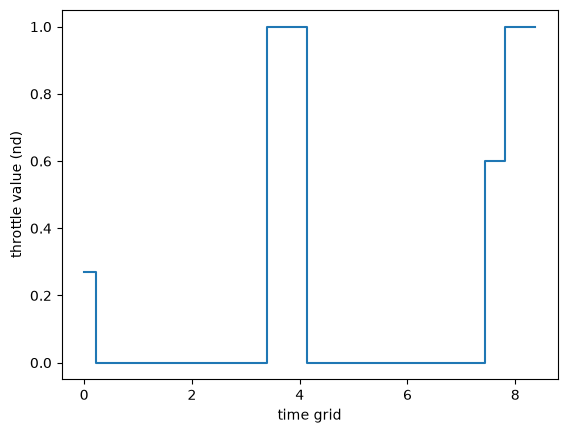

In [82]:
udp.plot_throttle(pop.champion_x)